# Hit filter in hps-java: reconstruction with and without `SvtHitFilterDriver`

End-to-end test of the filter developed in `SVT_Hit_Filter_ML.ipynb`. The same overlay-MC readout files
(tritrig + pulser, run 14272 conditions, files 0561–0600, never used for training or testing) are reconstructed
with the production steering `PhysicsRun2021MCRecon_KF_WithSpacing_pass5_physics_HitSmear_HitKill_14272.lcsim`,
the same hps-java jar and the same conditions:
- **baseline**: unchanged steering;
- **baseline, repeated**: the same again. The MC smearing drivers (`RawHitTimeSmearer`, `StripHitNHitsSmearer`,
  `TrackTimeSmearer`) use unseeded random numbers, so two baseline passes differ. Their difference is the
  **noise floor** of any comparison between two reconstructions;
- **filtered**: `SvtHitFilterDriver` inserted before `KalmanPatRecDriver` (model `models/svt_hitfilter_v1.txt`,
  `timeOffset` −0.1 ns, MC working point).

All are converted to MiniDSTs with the production `make_mini_dst` (`hps-java/run_recon_test.sh`) and analysed with
`Analysis.svt_tracking`. Since the KF really runs on the filtered hits, this measures what the offline study could
only estimate: track finding, purity, wrong hits, resolution and vertexing.

**Contents**
1. Hits, tracks and run time
2. Efficiency tiers, wrong and missing hits
3. Paired comparison: which particles are lost or gained, against the noise floor
4. Vertices: background that reaches a displaced-vertex analysis
5. Summary

In [1]:
import sys, re, glob
sys.path.insert(0, "../..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ROOT
from Analysis import svt_tracking as st

st.setup(n_threads=32)
st.mpl_style()
TEST_DIR = "/net/data/endeavour2/HPS/physrun2021/home_made_mc/hitfilter_test"
FILES = "tritrig_pulser_3pt74_recon_0[56][0-9][0-9].root"          # 0561-0600
S = {k: st.Sample(k, lab, f"{TEST_DIR}/{k}/{FILES}", "", t0=-0.1)
     for k, lab in (("baseline", "baseline"), ("baseline2", "baseline, repeated"), ("filtered", "with hit filter"))}
COL = {"baseline": st.COLORS["muted"], "baseline2": st.COLORS["pure"], "filtered": st.COLORS["overlay"]}
CATS = st.CATEGORIES
SVT = "tp_n_layers >= 8"
ECAL = "tp_acc && !tp_gap"
for k, s in S.items():
    print(f"{k}: {len(s.files())} files")
assert len({tuple(re.sub(r'.*_', '', f) for f in s.files()) for s in S.values()}) == 1, "samples must have the same files"

baseline: 70 files
baseline2: 70 files
filtered: 70 files


In [2]:
LB, NH = st.layer_bins(), st.int_bins(5, 14)
def book(df):
    h = {"n_events": st.book_hist(df, "1", (1, 0, 2)),
         "bkg_layer": st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 0"),
         "mc_layer": st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 1"),
         "trk_matched": st.book_ratio(df, "trk_nhits", "trk_matched", (1, 0, 100)),
         "trk_nomc": st.book_ratio(df, "trk_nhits", "trk_particle < 0", (1, 0, 100)),
         "trk_intime": st.book_ratio(df, "trk_nhits", "abs(trk_time_rel) < 6", (1, 0, 100)),
         "matched_vs_nh": st.book_ratio(df, "trk_nhits", "trk_matched", NH, where="abs(trk_time_rel) < 6"),
         "dp": st.book_hist2d(df, "trk_nhits", "trk_dp_rel", NH, (800, -1, 1), where="trk_matched"),
         "wrong": st.book_ratio_of(df, "svt::mask_to_layers(trk_wrong[trk_matched])", "svt::mask_to_layers(trk_layers[trk_matched])", LB),
         "missing": st.book_ratio_of(df, "svt::mask_to_layers(tp_missing[tp_found])", "svt::mask_to_layers(tp_layers[tp_found])", LB),
         "nwrong": st.book_hist(df, "trk_n_wrong", st.int_bins(0, 7), where="trk_matched")}
    for c, sel in CATS.items():
        h[c] = {"tiers_svt": st.book_hist(df, "tp_tier", st.int_bins(0, 5), where=f"{sel['tp']} && {SVT}"),
                "tiers_ecal": st.book_hist(df, "tp_tier", st.int_bins(0, 5), where=f"{sel['tp']} && {ECAL}")}
    return h
DF = {k: st.load(s) for k, s in S.items()}
H = {k: book(df) for k, df in DF.items()}
st.run(H)
for k in H:
    print(f"{k}: {H[k]['n_events'].counts[0]:,.0f} events")

baseline: 116,412 events
baseline2: 116,412 events
filtered: 116,412 events


## 1. Hits, tracks and run time

In [3]:
def ms_per_event(k):
    vals = []
    for f in S[k].files():
        m = re.findall(r"Event processing took ([0-9.]+) ms/event", open(f.replace(".root", ".log"), errors="ignore").read())
        if m: vals.append(float(m[-1]))
    return np.mean(vals) if vals else np.nan
rows = {}
for k in H:
    h, n = H[k], H[k]["n_events"].counts[0]
    rows[S[k].label] = {"background hits / event": h["bkg_layer"].counts.sum() / n, "MC hits / event": h["mc_layer"].counts.sum() / n,
                        "tracks / event": h["trk_matched"].total.sum() / n, "matched to trident e±": h["trk_matched"].integral()[0],
                        "no MC hit at all": h["trk_nomc"].integral()[0], "in time (|t| < 6 ns)": h["trk_intime"].integral()[0],
                        "matched tracks with 0 wrong hits": h["nwrong"].counts[0] / h["nwrong"].counts.sum(),
                        "recon time [ms / event]": ms_per_event(k)}
pd.DataFrame(rows).T.round(3)

,background hits / event,MC hits / event,tracks / event,matched to trident e±,no MC hit at all,in time (|t| < 6 ns),matched tracks with 0 wrong hits,recon time [ms / event]
baseline,119.620,18.016,2.655,0.504,0.421,0.553,0.616,89.048
"baseline, repeated",119.620,18.013,2.654,0.504,0.421,0.552,0.615,92.314
with hit filter,58.862,17.928,2.179,0.610,0.316,0.702,0.696,84.968


/tmp/ipykernel_524670/2235939990.py:20: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


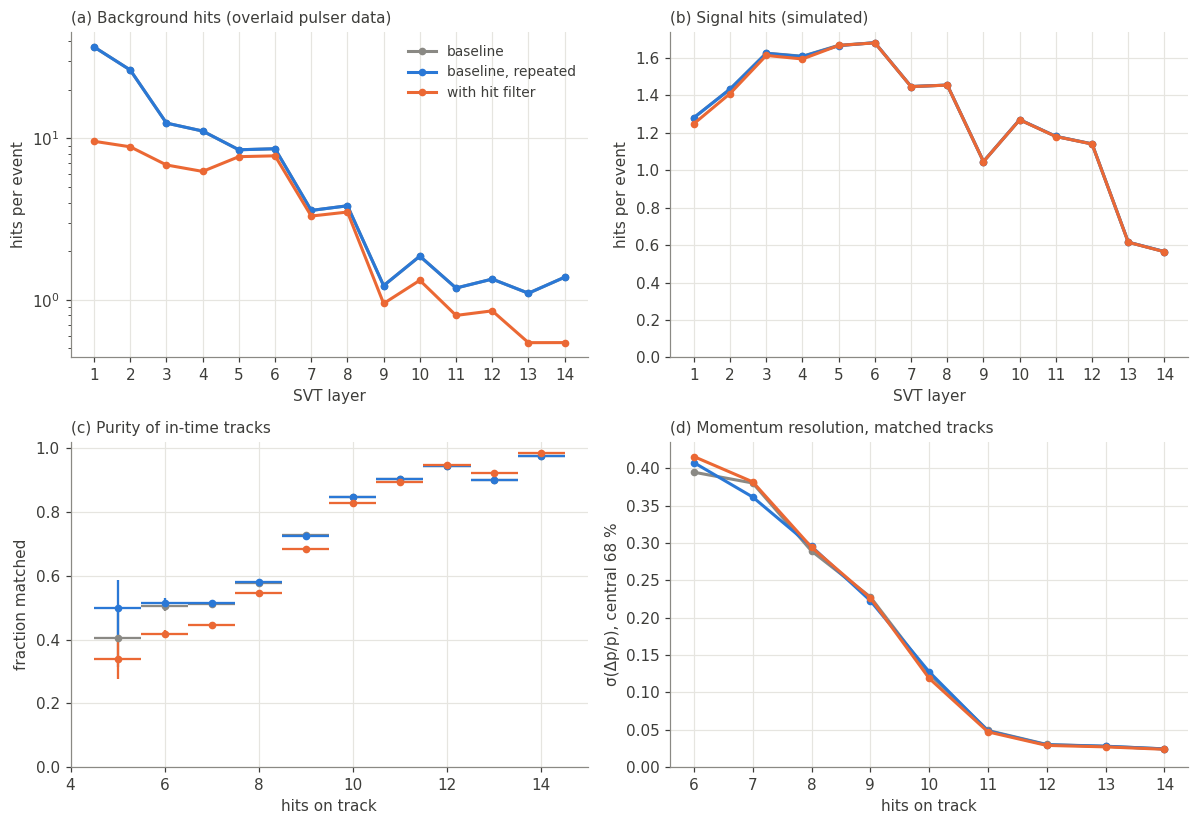

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.6))
(a, a2), (b, c) = axes
for k in H:
    n = H[k]["n_events"].counts[0]
    a.plot(st.LAYERS, H[k]["bkg_layer"].counts / n, "o-", color=COL[k], label=S[k].label, ms=4)
    a2.plot(st.LAYERS, H[k]["mc_layer"].counts / n, "o-", color=COL[k], label=S[k].label, ms=4)
    st.plot_ratio(b, H[k]["matched_vs_nh"], label=S[k].label, color=COL[k], min_total=20)
    med, w = st.central_width(H[k]["dp"])
    c.plot(NH[:-1] + 0.5, w, "o-", color=COL[k], label=S[k].label, ms=4)
for x in (a, a2):
    x.set_xticks(st.LAYERS)
a.set_yscale("log")
st.style(a, "SVT layer", "hits per event", "(a) Background hits (overlaid pulser data)")
a2.set_ylim(bottom=0)
st.style(a2, "SVT layer", "hits per event", "(b) Signal hits (simulated)", legend=False)
b.set_ylim(0, 1.02)
st.style(b, "hits on track", "fraction matched", "(c) Purity of in-time tracks", legend=False)
c.set_ylim(bottom=0)
st.style(c, "hits on track", "σ(Δp/p), central 68 %", "(d) Momentum resolution, matched tracks", legend=False)
plt.tight_layout(); plt.show()

- **The filter does in reconstruction what it was trained to do.** Background hits fall from 119.6 to 58.9 per
  event (L1: 37 → 10), while the simulated hits are almost untouched (18.02 → 17.93 per event).
- **The repeated baseline is identical in all averages.** The MC smearing in recon is random, but on 116 k events it
  changes none of these numbers by more than 0.1 %. Any difference larger than that between baseline and filter is
  caused by the filter.
- **Fewer, better tracks.** Tracks per event drop from 2.66 to 2.18. The fraction matched to a trident particle
  rises from 50 % to 61 %, background-only tracks fall from 42 % to 32 %, and in-time tracks rise from 55 % to 70 %.
- **At a fixed hit count, tracks with ≥ 10 hits have unchanged purity and resolution.** Short tracks (5–9 hits)
  become less pure (0.51 → 0.42 matched at 6 hits): with fewer background hits left, the short tracks that survive
  are relatively more often background combinations. The overall gain comes from real tracks keeping their own
  hits.
- **Speed.** Measured on a shared machine, the run time is 89 and 92 ms/event for the two baselines and 85 ms/event
  with the filter. An earlier test under equal load gave 72 → 57 ms. The filter is faster, by between 5 % and 20 %.

## 2. Efficiency (tiers) and hits on tracks

Tiers are cumulative (see `Analysis.svt_tracking.TIER_DOC`): *found* (a track matched to the particle), *clean*
(at most one wrong hit), *good p* (|Δp/p| < 0.15), *in time* (|t| < 6 ns) and *ECal match* (the track is linked
to the particle's ECal cluster).

In [5]:
def tiers(den):
    rows = []
    for k in H:
        for c in CATS:
            eff, err, n = st.tier_efficiency(H[k][c][den])
            rows.append(dict(sample=S[k].label, category=c, N=int(n), **dict(zip(st.TIERS, eff))))
    return pd.DataFrame(rows).set_index(["category", "sample"]).sort_index().round(4)
print("SVT acceptance (>= 8 layers with a truth hit)")
display(tiers("tiers_svt").drop(columns="ECal match"))
print("ECal acceptance, outside the beam gap")
tiers("tiers_ecal")

SVT acceptance (>= 8 layers with a truth hit)


N   found   clean  good p  in time
category  sample                                                    
e+ bottom baseline            56270  0.9862  0.8665  0.8065   0.7801
          baseline, repeated  56275  0.9860  0.8659  0.8054   0.7793
          with hit filter     56208  0.9863  0.8930  0.8306   0.8086
e+ top    baseline            54520  0.9835  0.8091  0.7728   0.7437
          baseline, repeated  54524  0.9819  0.8060  0.7700   0.7407
          with hit filter     54476  0.9806  0.8425  0.8033   0.7805
e- bottom baseline            21693  0.9239  0.8061  0.6648   0.6432
          baseline, repeated  21693  0.9238  0.8001  0.6636   0.6425
          with hit filter     21469  0.9290  0.8356  0.6942   0.6780
e- top    baseline            22853  0.9299  0.7752  0.7005   0.6739
          baseline, repeated  22851  0.9302  0.7734  0.7007   0.6740
          with hit filter     22624  0.9333  0.8146  0.7371   0.7191

ECal acceptance, outside the beam gap


N   found   clean  good p  in time  \
category  sample                                                       
e+ bottom baseline            46696  0.9943  0.9064  0.8672   0.8451   
          baseline, repeated  46696  0.9940  0.9068  0.8676   0.8458   
          with hit filter     46696  0.9949  0.9291  0.8895   0.8713   
e+ top    baseline            47201  0.9918  0.8426  0.8151   0.7902   
          baseline, repeated  47201  0.9908  0.8408  0.8131   0.7874   
          with hit filter     47201  0.9904  0.8741  0.8438   0.8251   
e- bottom baseline             8665  0.9438  0.8345  0.6854   0.6665   
          baseline, repeated   8665  0.9454  0.8257  0.6806   0.6635   
          with hit filter      8665  0.9474  0.8541  0.7066   0.6928   
e- top    baseline             8908  0.9403  0.7841  0.7031   0.6834   
          baseline, repeated   8908  0.9404  0.7785  0.7009   0.6791   
          with hit filter      8908  0.9401  0.8125  0.7263   0.7119   

                              ECal match  
category  sample                          
e+ bottom baseline                0.8271  
          baseline, repeated      0.8287  
          with hit filter         0.8519  
e+ top    baseline                0.7794  
          baseline, repeated      0.7777  
          with hit filter         0.8133  
e- bottom baseline                0.5827  
          baseline, repeated      0.5753  
          with hit filter         0.5998  
e- top    baseline                0.6141  
          baseline, repeated      0.6104  
          with hit filter         0.6359

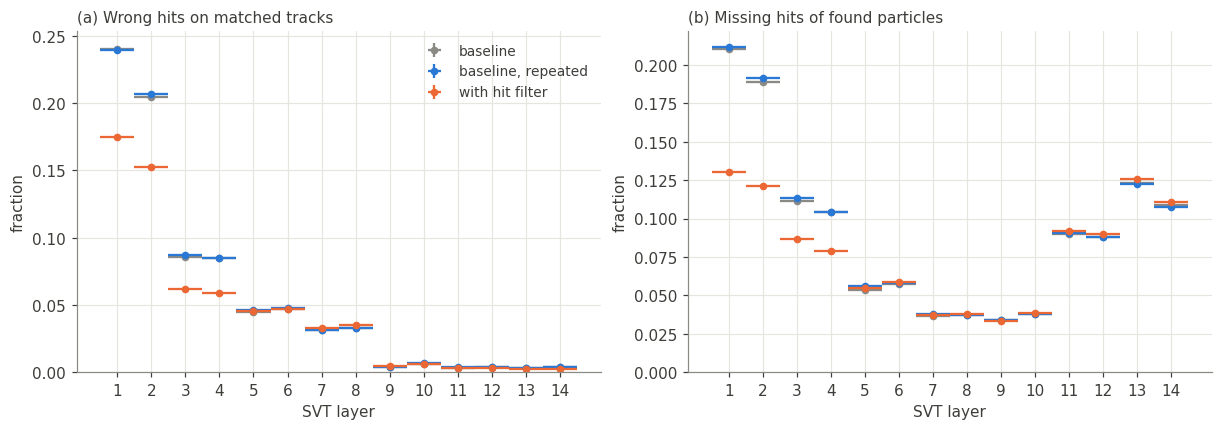

layer,1,2,3,4,5,6,7,8,9,10,11,12,13,14
wrong (baseline),0.2402,0.2049,0.0854,0.0852,0.0451,0.0471,0.0312,0.0329,0.0042,0.0062,0.0035,0.0037,0.0034,0.0040
"wrong (baseline, repeated)",0.2395,0.2071,0.0871,0.0848,0.0459,0.0474,0.0315,0.0330,0.0041,0.0068,0.0035,0.0042,0.0031,0.0042
wrong (with hit filter),0.1745,0.1524,0.0617,0.0589,0.0453,0.0473,0.0332,0.0352,0.0046,0.0059,0.0033,0.0033,0.0021,0.0025
missing (baseline),0.2106,0.1892,0.1113,0.1043,0.0538,0.0574,0.0367,0.0372,0.0338,0.0376,0.0898,0.0877,0.1234,0.1088
"missing (baseline, repeated)",0.2117,0.1915,0.1131,0.1041,0.0561,0.0583,0.0377,0.0369,0.0342,0.0381,0.0908,0.0881,0.1223,0.1074
missing (with hit filter),0.1302,0.1214,0.0864,0.0786,0.0548,0.0585,0.0374,0.0381,0.0332,0.0386,0.0922,0.0903,0.1257,0.1107


In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for k in H:
    st.plot_ratio(a, H[k]["wrong"], label=S[k].label, color=COL[k], min_total=50)
    st.plot_ratio(b, H[k]["missing"], label=S[k].label, color=COL[k], min_total=50)
for x, t in ((a, "(a) Wrong hits on matched tracks"), (b, "(b) Missing hits of found particles")):
    x.set_xticks(st.LAYERS); x.set_ylim(bottom=0)
    st.style(x, "SVT layer", "fraction", t, legend=(x is a))
plt.show()
pd.DataFrame({f"{w} ({S[k].label})": np.round(H[k][w].eff, 4) for w in ("wrong", "missing") for k in H},
             index=pd.Index(st.LAYERS, name="layer")).T

- **Track quality improves in every category, well beyond the noise floor.** The two baselines agree to
  0.1–0.6 points in every tier. With the filter, "clean" gains 2.5–4 points, "good p" 2–3.5 and "in time" 3–4.5.
- **Full chain to the ECal match, positrons (ECal acceptance):** 0.827 → 0.852 bottom and 0.779 → 0.813 top.
  Electrons: 0.583 → 0.600 bottom and 0.614 → 0.636 top.
- **The KF now takes the correct hit.**
  - L1/L2 wrong hits: 24.0 %/20.5 % → 17.5 %/15.2 %.
  - L1/L2 missing hits: 21.1 %/18.9 % → 13.0 %/12.1 %.
  - L3/L4: wrong hits 8.5 % → 6.0 %, missing hits 11 % → 8 %.
  - L5–L14 are unchanged, as expected from the small background there.
- *Note:* in the SVT acceptance the number of particles N differs slightly between samples. The acceptance counts
  recon-level truth hits, and the filter removes a few of them. §3 avoids this by following each particle.

## 3. Paired comparison: which particles are lost or gained

All reconstructions run on identical events, so each truth particle can be followed: *lost* = found in the
baseline but not in the other pass, *gained* = the reverse. The repeated baseline gives the same numbers for two
passes **without** the filter; only changes beyond this noise floor are caused by the filter.

The net change is (gained − lost) / found. Its uncertainty, √(lost + gained) / found, assumes independent flips.
The second column in each pair checks this: the baseline-vs-baseline net change should be compatible with zero
within it.

In [7]:
ROOT.ROOT.DisableImplicitMT()     # sequential: rdfentry_ is then the entry number of the chain, identical in all samples
cols = ["rdfentry_", "event_number", "tp_idx", "tp_found", "tp_pos", "tp_top", "tp_acc", "tp_gap", "tp_n_layers"]
def particles(s):
    a = st.load(s).AsNumpy(cols)
    n = np.array([len(v) for v in a["tp_idx"]])
    d = {c: np.concatenate([np.asarray(v) for v in a[c]]) for c in cols[2:]}
    d["entry"], d["event_number"] = np.repeat(a["rdfentry_"], n), np.repeat(a["event_number"], n)
    df_ = pd.DataFrame(d).set_index(["entry", "tp_idx"])
    assert df_.index.is_unique
    return df_
PP = {k: particles(s) for k, s in S.items()}
P = PP["baseline"].copy()
for k in ("baseline2", "filtered"):
    assert len(PP[k]) == len(P) and (PP[k]["event_number"].values == P["event_number"].values).all()   # same events, same order
    P[f"found_{k}"] = PP[k]["tp_found"].values.astype(bool)
P["found"] = P["tp_found"].astype(bool)
P["cat"] = np.where(P.tp_pos == 1, "e+", "e-") + " " + np.where(P.tp_top == 1, "top", "bottom")
rows = []
for acc_name, m in (("SVT acceptance", P.tp_n_layers >= 8), ("ECal acceptance, no gap", (P.tp_acc == 1) & (P.tp_gap == 0))):
    for c in ["all"] + sorted(P.cat.unique()):
        q = P[m] if c == "all" else P[m & (P.cat == c)]
        r = {"acceptance": acc_name, "category": c, "found (baseline)": int(q.found.sum())}
        for k, lab in (("baseline2", "repeat"), ("filtered", "filter")):
            lost, gained = int((q.found & ~q[f"found_{k}"]).sum()), int((~q.found & q[f"found_{k}"]).sum())
            nb_ = r["found (baseline)"]
            r.update({f"lost ({lab})": lost, f"gained ({lab})": gained, f"net [%] ({lab})": 100 * (gained - lost) / nb_,
                      f"± [%] ({lab})": 100 * np.sqrt(lost + gained) / nb_})
        rows.append(r)
paired = pd.DataFrame(rows).set_index(["acceptance", "category"])
paired.round(2)

found (baseline)  lost (repeat)  \
acceptance              category                                     
SVT acceptance          all                  150405           2408   
                        e+ bottom             55493            463   
                        e+ top                53620            630   
                        e- bottom             20042            703   
                        e- top                21250            612   
ECal acceptance, no gap all                  109798            750   
                        e+ bottom             46432            192   
                        e+ top                46812            310   
                        e- bottom              8178            124   
                        e- top                 8376            124   

                                   gained (repeat)  net [%] (repeat)  \
acceptance              category                                       
SVT acceptance          all                   2196             -0.14   
                        e+ bottom              447             -0.03   
                        e+ top                 539             -0.17   
                        e- bottom              629             -0.37   
                        e- top                 581             -0.15   
ECal acceptance, no gap all                    704             -0.04   
                        e+ bottom              177             -0.03   
                        e+ top                 264             -0.10   
                        e- bottom              138              0.17   
                        e- top                 125              0.01   

                                   ± [%] (repeat)  lost (filter)  \
acceptance              category                                   
SVT acceptance          all                  0.05           3116   
                        e+ bottom            0.05            538   
                        e+ top               0.06            800   
                        e- bottom            0.18            893   
                        e- top               0.16            885   
ECal acceptance, no gap all                  0.03            832   
                        e+ bottom            0.04            166   
                        e+ top               0.05            377   
                        e- bottom            0.20            133   
                        e- top               0.19            156   

                                   gained (filter)  net [%] (filter)  \
acceptance              category                                       
SVT acceptance          all                   2624             -0.33   
                        e+ bottom              511             -0.05   
                        e+ top                 611             -0.35   
                        e- bottom              758             -0.67   
                        e- top                 744             -0.66   
ECal acceptance, no gap all                    819             -0.01   
                        e+ bottom              190              0.05   
                        e+ top                 311             -0.14   
                        e- bottom              164              0.38   
                        e- top                 154             -0.02   

                                   ± [%] (filter)  
acceptance              category                   
SVT acceptance          all                  0.05  
                        e+ bottom            0.06  
                        e+ top               0.07  
                        e- bottom            0.20  
                        e- top               0.19  
ECal acceptance, no gap all                  0.04  
                        e+ bottom            0.04  
                        e+ top               0.06  
                        e- bottom            0.21  
                        e- top               0.21

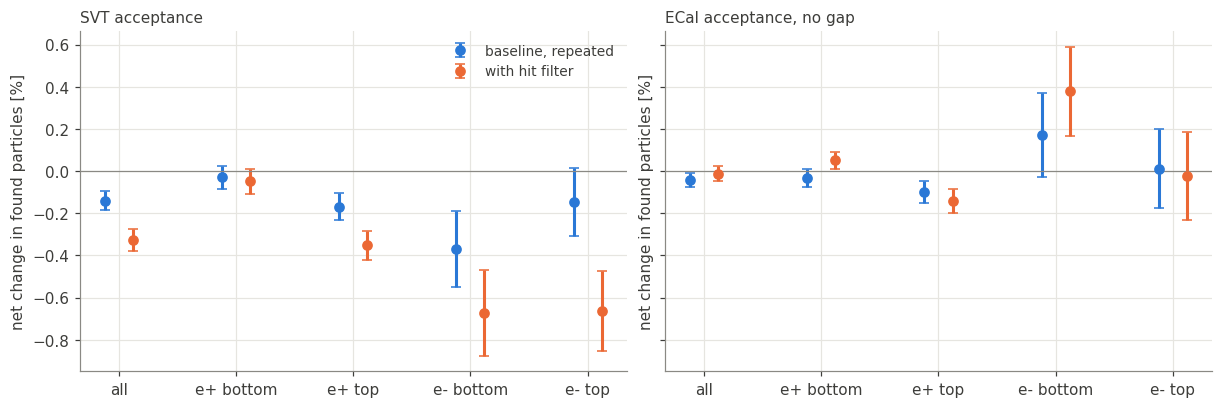

In [8]:
# Net change per category with its uncertainty: filter (orange) against the noise floor (blue)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, acc in zip(axes, ("SVT acceptance", "ECal acceptance, no gap")):
    q = paired.loc[acc]
    x = np.arange(len(q))
    for k, lab, dx in (("repeat", "baseline, repeated", -0.12), ("filter", "with hit filter", 0.12)):
        ax.errorbar(x + dx, q[f"net [%] ({k})"], yerr=q[f"± [%] ({k})"], fmt="o", ms=6, capsize=3,
                    color=COL["baseline2" if k == "repeat" else "filtered"], label=lab)
    ax.axhline(0, color=st.COLORS["muted"], lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(q.index)
    st.style(ax, None, "net change in found particles [%]", acc, legend=(ax is axes[0]))
plt.show()

- **The noise floor is large.** Between the two identical baseline jobs, 1.6 % of the found particles are lost and
  1.5 % gained, from the random smearing in MC reconstruction. Even the repeat shows a net −0.14 ± 0.05 %, so the
  statistical errors underestimate the true run-to-run spread. The filter has to be compared to the repeat, not to
  zero.
- **ECal acceptance (the physics-relevant sample): no loss.** Filter −0.01 ± 0.04 %, repeat −0.04 ± 0.03 %. No
  category differs from the repeat by more than 1.5 σ.
- **SVT acceptance: a small loss beyond the noise floor.** Filter −0.33 ± 0.05 %, repeat −0.14 ± 0.05 %. It comes
  from:
  - electrons, −0.67 ± 0.20 % in both halves (repeat −0.37 and −0.15 %);
  - top positrons, −0.35 vs −0.17 %.
  These are mostly marginal tracks outside the ECal acceptance, with 8–10 layers hit. There a single lost hit makes
  the track unfindable (see `Tracking_Efficiency_SVT_Hits.ipynb` §2b).
- **The filter therefore does not gain tracks.** It changes which hits the found tracks use (§2), not whether they
  are found.

## 4. Vertices: background that reaches a displaced-vertex analysis

Better tracks should mean fewer badly reconstructed vertices. All tritrig pairs come from the target, so any V0
reconstructed far downstream of it is the prompt background that limits the displaced-vertex (A′) search. Wrong
L1/L2 hits are a known source of this tail.

The final analysis cuts are not available yet. A **loose, generic preselection** stands in for them: it is defined
in the dictionary `PRESEL` below, so the real cuts can be dropped in later. Candidates are unconstrained KF V0s
(`v0_type == 1`). A *true pair* has both tracks matched to the trident e⁻ and e⁺. The tail is counted per event
with z beyond z_cut, relative to the median z of true pairs.

In [9]:
PRESEL = {"track time |t| < 6 ns (both)": "(abs(em_t) < 6) & (abs(ep_t) < 6)",
          "track time difference < 4 ns": "abs(em_t - ep_t) < 4",
          "track χ²/ndf < 6 (both)": "(em_chi2ndf < 6) & (ep_chi2ndf < 6)",
          "vertex χ² < 20": "chi2 < 20",
          "e⁻ p < 2.6 GeV (FEE)": "em_p < 2.6",
          "1.0 < p(e⁺e⁻) < 4.5 GeV": "(psum > 1.0) & (psum < 4.5)"}
V0COLS = {"z": "v0_vertex_z[v_sel]", "chi2": "v0_vertex_chi2[v_sel]", "psum": "v0_p[v_sel]", "mass": "v0_mass[v_sel]",
          "em_p": "v0_em_p[v_sel]", "ep_p": "v0_ep_p[v_sel]"}
for s_ in ("em", "ep"):
    i = f"ROOT::RVec<int>(v0_{s_}_track)[v_sel]"
    V0COLS.update({f"{s_}_t": f"svt::take_or(ROOT::RVec<double>(trk_time_rel), {i}, 999.)",
                   f"{s_}_chi2ndf": f"svt::take_or(ROOT::RVec<double>(track_chi2) / ROOT::RVec<double>(track_ndf), {i}, 99.)",
                   f"{s_}_nh": f"svt::take_or(ROOT::RVec<int>(trk_nhits), {i}, 0)",
                   f"{s_}_matched": f"svt::take_or(ROOT::RVec<int>(trk_matched), {i}, 0)",
                   f"{s_}_pos": f"svt::take_or(ROOT::RVec<int>(trk_pos), {i}, 0)",
                   f"{s_}_layers": f"svt::take_or(ROOT::RVec<int>(trk_layers), {i}, 0)",
                   f"{s_}_wrong": f"svt::take_or(ROOT::RVec<int>(trk_wrong), {i}, 0)"})
ROOT.ROOT.EnableImplicitMT(32)
def v0_frame(k):
    df = st.load(S[k]).Define("v_sel", "v0_type == 1")
    for c, e in V0COLS.items():
        df = df.Define(f"V_{c}", e)
    a = df.AsNumpy([f"V_{c}" for c in V0COLS])
    v = pd.DataFrame({c: np.concatenate([np.asarray(x) for x in a[f"V_{c}"]]) for c in V0COLS})
    v["true_pair"] = (v.em_matched == 1) & (v.ep_matched == 1) & (v.em_pos == 0) & (v.ep_pos == 1)
    v["L1L1"] = ((v.em_layers & 1) > 0) & ((v.ep_layers & 1) > 0)
    v["wrong_L1L2"] = ((v.em_wrong | v.ep_wrong) & 0b11) > 0
    v["presel"] = np.ones(len(v), bool)
    for cut in PRESEL.values():
        v["presel"] &= v.eval(cut)
    return v
V = {k: v0_frame(k) for k in S}
NEV = {k: H[k]["n_events"].counts[0] for k in H}
Z0 = float(np.median(V["baseline"].query("presel & true_pair").z))
print(f"median z of true pairs (baseline, preselected): {Z0:.2f} mm")
rows = {}
for k, v in V.items():
    p = v[v.presel]
    tp_ = p[p.true_pair]
    rows[S[k].label] = {"V0 / event (all)": len(v) / NEV[k], "preselected V0 / event": len(p) / NEV[k],
                        "true pairs among preselected": p.true_pair.mean(), "L1L1 among preselected": p.L1L1.mean(),
                        "true pairs: σ68(z) [mm]": np.diff(np.percentile(tp_.z, [16, 84]))[0] / 2,
                        "true pairs: σ68(z), L1L1 [mm]": np.diff(np.percentile(tp_[tp_.L1L1].z, [16, 84]))[0] / 2,
                        "true pairs with a wrong L1/L2 hit": tp_.wrong_L1L2.mean()}
pd.DataFrame(rows).T.round(4)

median z of true pairs (baseline, preselected): -1.04 mm


,V0 / event (all),preselected V0 / event,true pairs among preselected,L1L1 among preselected,true pairs: σ68(z) [mm],"true pairs: σ68(z), L1L1 [mm]",true pairs with a wrong L1/L2 hit
baseline,1.0058,0.1746,0.9001,0.6857,1.5630,1.3121,0.3035
"baseline, repeated",1.0029,0.1749,0.9008,0.6878,1.5868,1.3469,0.3077
with hit filter,0.7253,0.1860,0.9024,0.7045,1.4816,1.2512,0.2060


/tmp/ipykernel_524670/1034402796.py:22: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


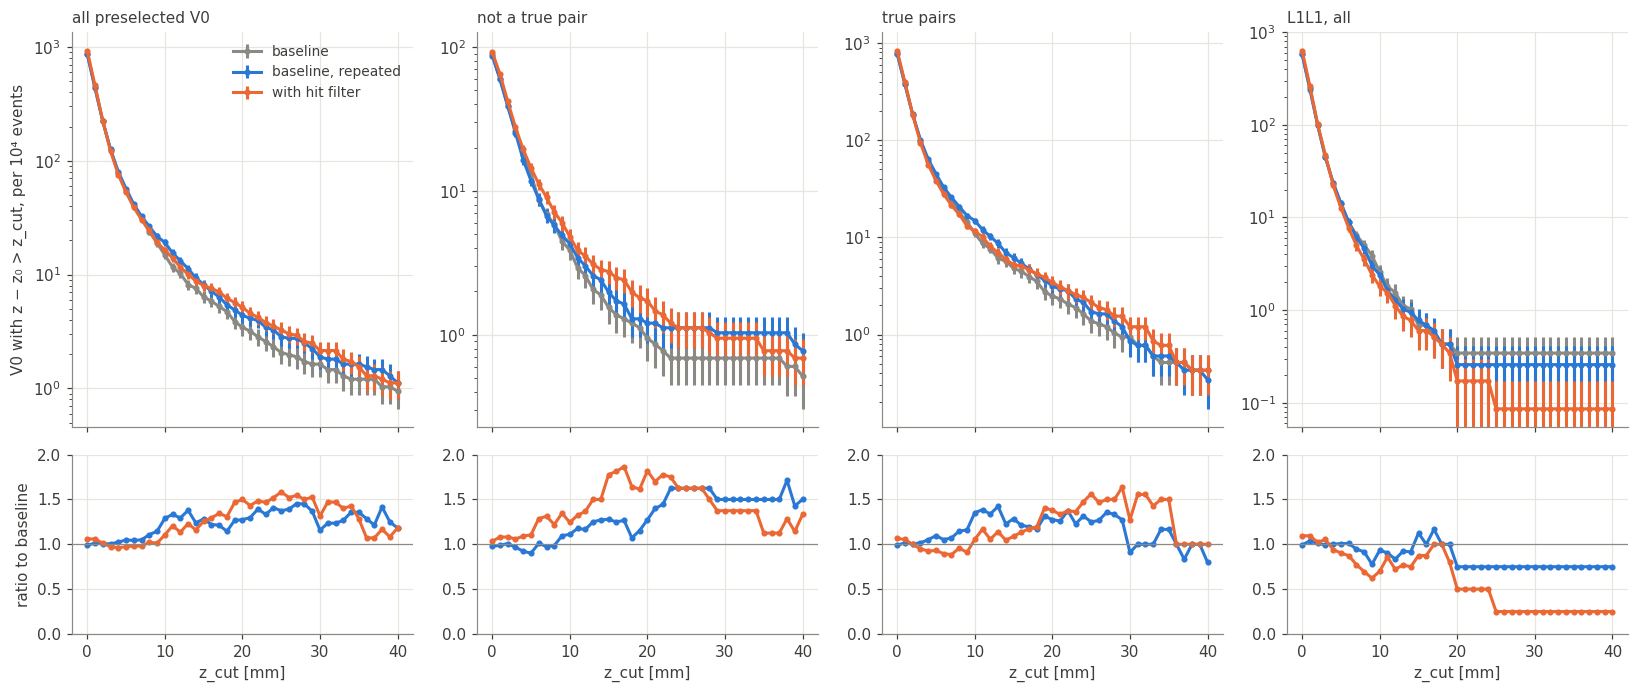

V0 per 10^4 events beyond z_cut (Poisson errors; the samples share their events, so differences are better determined)


baseline baseline, repeated  \
all preselected V0 z − z₀ > 5 mm   54.3 ± 2.2         57.0 ± 2.2   
                   z − z₀ > 10 mm  14.9 ± 1.1         19.2 ± 1.3   
                   z − z₀ > 15 mm   6.4 ± 0.7          8.2 ± 0.8   
                   z − z₀ > 20 mm   3.4 ± 0.5          4.4 ± 0.6   
not a true pair    z − z₀ > 5 mm   13.1 ± 1.1         11.8 ± 1.0   
                   z − z₀ > 10 mm   3.9 ± 0.6          4.3 ± 0.6   
                   z − z₀ > 15 mm   1.5 ± 0.4          2.0 ± 0.4   
                   z − z₀ > 20 mm   0.9 ± 0.3          1.2 ± 0.3   
true pairs         z − z₀ > 5 mm   41.2 ± 1.9         45.2 ± 2.0   
                   z − z₀ > 10 mm  11.0 ± 1.0         14.9 ± 1.1   
                   z − z₀ > 15 mm   4.8 ± 0.6          6.2 ± 0.7   
                   z − z₀ > 20 mm   2.5 ± 0.5          3.2 ± 0.5   
L1L1, all          z − z₀ > 5 mm   14.1 ± 1.1         14.2 ± 1.1   
                   z − z₀ > 10 mm   2.6 ± 0.5          2.4 ± 0.5   
                   z − z₀ > 15 mm   0.7 ± 0.2          0.8 ± 0.3   
                   z − z₀ > 20 mm   0.3 ± 0.2          0.3 ± 0.1   

                                  with hit filter  
all preselected V0 z − z₀ > 5 mm       52.8 ± 2.1  
                   z − z₀ > 10 mm      16.4 ± 1.2  
                   z − z₀ > 15 mm       8.0 ± 0.8  
                   z − z₀ > 20 mm       5.2 ± 0.7  
not a true pair    z − z₀ > 5 mm       14.4 ± 1.1  
                   z − z₀ > 10 mm       4.8 ± 0.6  
                   z − z₀ > 15 mm       2.7 ± 0.5  
                   z − z₀ > 20 mm       1.7 ± 0.4  
true pairs         z − z₀ > 5 mm       38.4 ± 1.8  
                   z − z₀ > 10 mm      11.6 ± 1.0  
                   z − z₀ > 15 mm       5.2 ± 0.7  
                   z − z₀ > 20 mm       3.4 ± 0.5  
L1L1, all          z − z₀ > 5 mm       12.7 ± 1.0  
                   z − z₀ > 10 mm       1.8 ± 0.4  
                   z − z₀ > 15 mm       0.6 ± 0.2  
                   z − z₀ > 20 mm       0.2 ± 0.1

In [10]:
zc = np.arange(0, 40.5, 1.0)
def tail(v, sel, k):
    z = v.loc[sel, "z"].values - Z0
    n = np.array([(z > c).sum() for c in zc])
    return 1e4 * n / NEV[k], 1e4 * np.sqrt(n) / NEV[k]
groups = (("all preselected V0", lambda v: v.presel), ("not a true pair", lambda v: v.presel & ~v.true_pair),
          ("true pairs", lambda v: v.presel & v.true_pair), ("L1L1, all", lambda v: v.presel & v.L1L1))
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for j, (gname, sel) in enumerate(groups):
    a, r = axes[0, j], axes[1, j]
    base, base_e = tail(V["baseline"], sel(V["baseline"]), "baseline")
    for k in V:
        n, e = tail(V[k], sel(V[k]), k)
        a.errorbar(zc, n, yerr=e, fmt="o-", ms=3, color=COL[k], label=S[k].label)
        if k != "baseline":
            ok = base > 0
            r.plot(zc[ok], n[ok] / base[ok], "o-", ms=3, color=COL[k])
    a.set_yscale("log")
    st.style(a, None, "V0 with z − z₀ > z_cut, per 10⁴ events" if j == 0 else None, gname, legend=(j == 0))
    r.axhline(1, color=st.COLORS["muted"], lw=0.8); r.set_ylim(0, 2)
    st.style(r, "z_cut [mm]", "ratio to baseline" if j == 0 else None, None, legend=False)
plt.tight_layout(); plt.show()
TZ = (5, 10, 15, 20)
tab = {}
for k in V:
    for gname, sel in groups:
        n, e = tail(V[k], sel(V[k]), k)
        for c in TZ:
            tab.setdefault((gname, f"z − z₀ > {c} mm"), {})[S[k].label] = f"{n[c]:.1f} ± {e[c]:.1f}"
print("V0 per 10^4 events beyond z_cut (Poisson errors; the samples share their events, so differences are better determined)")
pd.DataFrame(tab).T

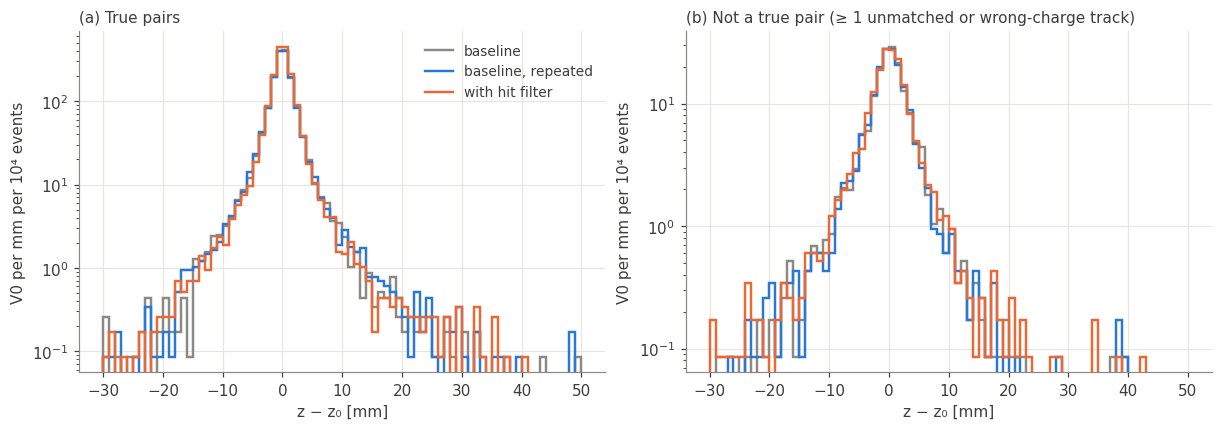

In [11]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
bz = np.linspace(-30, 50, 81)
for k in V:
    p = V[k][V[k].presel]
    for ax, m in ((a, p.true_pair), (b, ~p.true_pair)):
        h, _ = np.histogram(p.z[m] - Z0, bins=bz)
        ax.stairs(h / NEV[k] * 1e4, bz, color=COL[k], lw=1.6, label=S[k].label)
for ax, t in ((a, "(a) True pairs"), (b, "(b) Not a true pair (≥ 1 unmatched or wrong-charge track)")):
    ax.set_yscale("log")
    st.style(ax, "z − z₀ [mm]", "V0 per mm per 10⁴ events", t, legend=(ax is a))
plt.show()

- **Vertices are cleaner in their core.** Without the filter, 30 % of the preselected true pairs have a wrong L1 or
  L2 hit; with the filter, 21 %. The z resolution (σ68) of true pairs improves from 1.56 to 1.48 mm (repeat
  1.59 mm), and for L1L1 pairs from 1.31 to 1.25 mm (repeat 1.35 mm). L1L1 pairs rise from 68.6 % to 70.5 % of the
  preselected sample.
- **More good pairs pass the preselection.** There are 28 % fewer V0 candidates in total (fewer combinatorial
  pairs), but 6.5 % more preselected V0 per event. The extra pairs are true pairs (+6.8 %), because more tracks pass
  the time and χ² cuts. This is the vertex-level version of the full-chain gain in §2: no extra tracks are found,
  but more of the found tracks are usable.
- **The tails cannot be resolved with this sample.** Above z − z₀ = 10 mm the two baseline jobs already differ by
  up to 30 % (14.9 ± 1.1 vs 19.2 ± 1.3 per 10⁴ events). The random smearing decorrelates exactly the badly
  reconstructed vertices. The filter results lie inside this spread:
  - all preselected V0: 16.4 ± 1.2;
  - L1L1: 2.6 / 2.4 → 1.8 ± 0.4;
  - pairs that are not true pairs, beyond 15 mm: 1.5 / 2.0 → 2.7 ± 0.5.
- **What a real test needs:**
  - the tight selection cuts of the displaced-vertex analysis, which replace `PRESEL`;
  - a much larger sample, or a sample enriched in high-z background, since only a few dozen V0 lie beyond 20 mm
    here;
  - recon with fixed random seeds, so that baseline and filter differ only by the filter.

## 5. Summary

With the filter inserted by a steering change only, the hps-java reconstruction of 116 k held-out overlay-MC events
(files 0531–0600, three jobs: baseline, repeated baseline, with filter) gives:

| | baseline | repeated baseline | with filter |
|---|---|---|---|
| background hits / event | 119.6 | 119.6 | 58.9 |
| tracks matched to a trident e± | 50 % | 50 % | 61 % |
| net change in found particles, ECal acceptance | — | −0.04 ± 0.03 % | −0.01 ± 0.04 % |
| net change in found particles, SVT acceptance | — | −0.14 ± 0.05 % | −0.33 ± 0.05 % |
| e⁺ full chain (ECal match), bottom / top | 82.7 / 77.9 % | 82.9 / 77.8 % | 85.2 / 81.3 % |
| L1 wrong / missing hits | 24.0 / 21.1 % | 24.0 / 21.2 % | 17.5 / 13.0 % |
| preselected true V0 pairs / 10⁴ events | 1572 | 1576 | 1678 |
| true-pair σ68(z), all / L1L1 | 1.56 / 1.31 mm | 1.59 / 1.35 mm | 1.48 / 1.25 mm |

- **No tracks are gained, and in the ECal acceptance none are lost.** Outside it, about 0.2 % (electrons about
  0.4 %) are lost beyond the noise floor.
- **The found tracks are better.** They carry fewer wrong hits, have a better time and momentum, and match the ECal
  more often. As a result, 7 % more true pairs pass a loose vertex preselection, and the vertex core is 5 %
  narrower.
- **Whether less background survives a displaced-vertex selection is not yet answered.** The vertex tails are
  dominated by run-to-run randomness of the MC reconstruction. This needs the tight analysis cuts (drop-in for
  `PRESEL` in §4), more statistics, and seeded recon.

Next steps:
1. Tight-cut vertex analysis.
2. Seeded MC recon, to remove the noise floor.
3. A category-dependent working point, for the electrons outside the ECal acceptance.
4. The same test on run-14229 data.